attenuated min/max: 128 283
unattenuated min/max: 147 271


/var/folders/0l/y_qr08tx1pd0ng87pf9n29x00000gn/T/ipykernel_88295/2185439020.py:37: UserWarning: Adding colorbar to a different Figure <Figure size 1500x500 with 4 Axes> than <Figure size 1500x500 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)


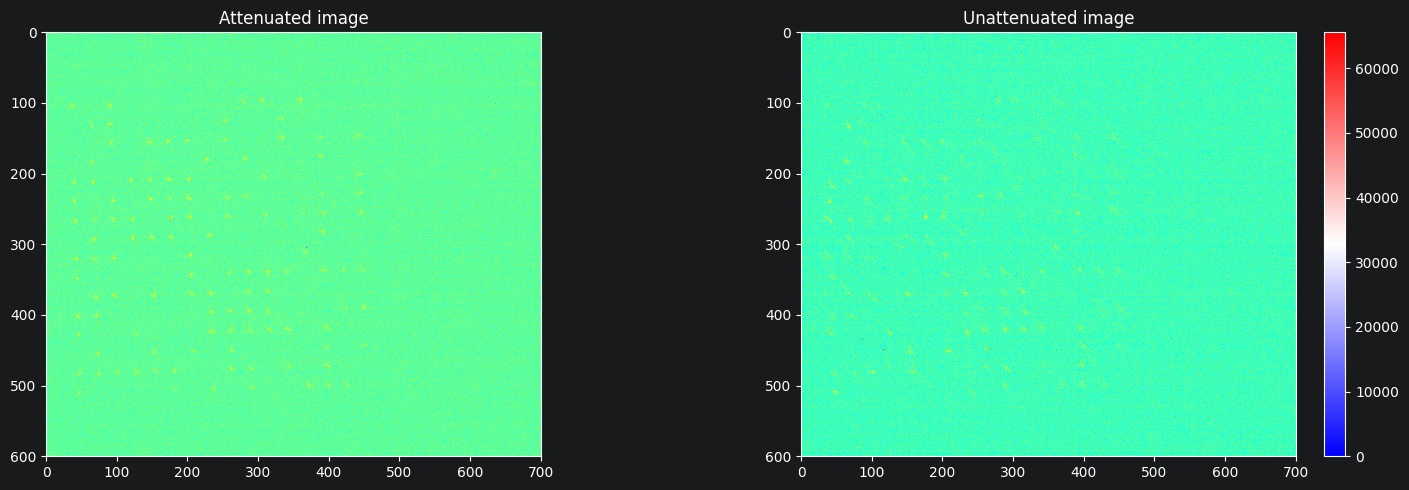

In [9]:
import h5py
import matplotlib.pyplot as plt

h5_path = "/Users/marone/Downloads/runs_4043_fast_imaging.h5"
image_index = 200

with h5py.File(h5_path, "r") as f:
    att = f["image_1"][image_index]
    non_att = f["image_2"][image_index]
    # labels = f["labels"][image_index]
    # sites = f["sites"][:]

print("attenuated min/max:", att.min(), att.max())
print("unattenuated min/max:", non_att.min(), non_att.max())
# print("labels:", labels)
#
vmin = min(att.min(), non_att.min())
vmax = max(att.max(), non_att.max())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(att, cmap="jet", vmin=att.min(), vmax=att.max())
# axes[0].scatter(sites[:, 0], sites[:, 1], s=20, c="white", marker="x")
axes[0].set_title("Attenuated image")
axes[0].set_xlim(0, att.shape[1])
axes[0].set_ylim(att.shape[0], 0)

axes[1].imshow(non_att, cmap="jet", vmin=non_att.min(), vmax=non_att.max())
# axes[1].scatter(sites[:, 0], sites[:, 1], s=20, c="white", marker="x")
axes[1].set_title("Unattenuated image")
axes[1].set_xlim(0, non_att.shape[1])
axes[1].set_ylim(non_att.shape[0], 0)

for ax in axes:
    ax.set_aspect("equal")

fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

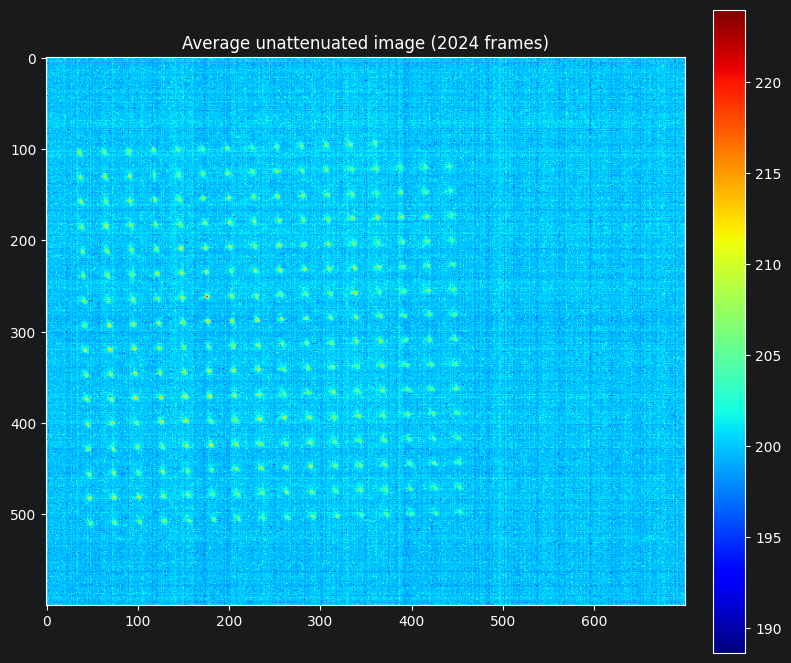

In [21]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

h5_path = "/Users/marone/Downloads/runs_4043_fast_imaging.h5"
image_key = "image_1"  # unattenuated images
batch_size = 64

with h5py.File(h5_path, "r") as f:
    images = f[image_key]
    n_images = images.shape[0]
    avg_unattenuated = np.zeros(images.shape[1:], dtype=np.float64)

    for start in range(0, n_images, batch_size):
        stop = min(start + batch_size, n_images)
        avg_unattenuated += images[start:stop].astype(np.float64).sum(axis=0)

avg_unattenuated /= n_images

plt.figure(figsize=(8, 7))
plt.imshow(avg_unattenuated, cmap="jet"
           )
plt.title(f"Average unattenuated image ({n_images} frames)")
plt.colorbar(fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [8]:
np.mean(non_att)

np.float64(199.9976880952381)